```{contents}
:local:
:depth: 2
```

# 3.5 Surrogate Models

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 8, Lesson 1: *Surrogate Modeling*
- Module 8, Lesson 2: *Regression vs Interpolation*
- Module 8, Lesson 3: *Sampling*
- Module 8, Lesson 4: *Linear Models and Regularization*
- Module 8, Lesson 5: *Intro to Modern Machine Learning Surrogates*
- Module 8, Lesson 6: *Optimization Solvers Used for Training ML Models*
- Module 8 (second week), Lesson 5: *Gaussian Process Models*
- Module 8 (second week), Lesson 6: *Neural Network Models*
- Module 8 (second week), Lesson 7: *Support Vector Regression*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Choose regression or interpolation for what the optimizer will do.
- Build a space-filling design and contrast it with model-based DoE.
- Distinguish optimization *for* training from optimization *with* a trained model.
- Derive the Lagrangian of the constrained LASSO and the dual of support vector regression.
- Compare four surrogate families on held-out data.
:::

In Topics 3.1–3.4 every evaluation went to the black box itself, but in this topic we will spend a few evaluations to build a cheap model of the black box, called a **surrogate**, and then let the equation-based optimizers of Topics 1.1–2.6 work on the model instead.

Regression, validation, regularization, Gaussian processes and neural networks are all taught in the companion book *Data Analytics for Chemical Engineers* (DA4CHE, https://www.medford.chbe.gatech.edu/DA4CHE/), so we will only recap each of them briefly with a pointer, and we will spend most of this topic on the parts that matter because the surrogate is going to be optimized.

## Why surrogates

A **surrogate model** (or metamodel) is a function $\hat f(x)$ that is fitted to input–output data from an expensive source, such as a simulator, an experiment, or plant data, and in machine-learning terms it is a supervised regression model. Unlike the source, the surrogate is cheap to evaluate and it has equations, so gradients, Pyomo and global solvers become available again.

The lectures motivate surrogates with **simulation-based optimization**, where the model of the process lives inside a simulator. Flowsheet and device models in Aspen, gPROMS or COMSOL are highly nonlinear, may be large systems of PDEs, and are often proprietary, which means that we cannot hand their equations to a solver. The lectures also rank the common surrogate families by complexity (i.e. the number of terms and the degree of nonlinearity), starting from linear regression and moving through polynomial regression, support vector regression and regression trees to neural networks. Radial basis functions, high-dimensional model representations and random forests are also used, but since trees and forests are piecewise constant they are awkward for gradient-based optimizers, so we will not use them here.

The lectures break **surrogate-based optimization** (SBO) into a series of steps: we choose the inputs and their bounds, collect initial data with a designed experiment, fit a surrogate, validate it on held-out data, optimize it, and then check the result against the black box, iterating if needed. This topic covers the first four steps, and Topic 3.6 closes the loop. Different samples or different surrogate types can give different optima, and noise makes the spread larger, so the optimum of a surrogate is only as good as the surrogate is near that optimum. A surrogate that is fitted to noisy data is itself uncertain, and we will return to this in Topic 5.2 with the direct-air-capture case study from the lectures (Hüllen et al., 2020), in {doc}`../5-uncertainty/Topic5.2-Robust_Optimization`.

For us the expensive source is the plant, so one evaluation of BB2 (where stacks A, B and C share $D = 1.2$, i.e. 240 kg H₂/h, and C takes whatever A and B leave) means running the fleet at a split $(x_A, x_B)$ until the power meter settles.

:::{exercise}
:label: ex-t35-sbo-steps

Map each SBO step onto the plant: what does an engineer physically do, and which step costs the most operating time?
:::

## Regression or interpolation: a choice made for optimization

A surrogate that passes through every sample **interpolates** the data, while one that minimizes an error without necessarily hitting the samples **regresses** the data. The lectures pair this with a second distinction between **parametric** models (linear, polynomial), which have a fixed number of parameters that each have an interpretation, and **nonparametric** models (Gaussian processes, SVR, neural networks), which have parameters without a direct meaning and whose number of parameters often grows with the data. Gaussian processes interpolate by default, while most networks and SVRs regress.

This choice also shapes the optimization problem that follows, since the number of nonlinear terms in the surrogate sets the size of that problem, which matters most when several constraints are surrogates. The convexity of the surrogates decides whether a local solver can be trusted (Topic 1.1), and the quality of the fit near the optimum sets the quality of the answer. Interpolators need validation even more than regressors do, because their training error is zero by construction.

The optimizer will go to the lowest point of the surrogate, so it is important to think about where that point comes from. If the data come from a noise-free simulator, an interpolator is honest at every sample we paid for, but if the data are noisy it will reproduce the noise as well, which means that its minimum tends to sit at whichever sample got the luckiest noise draw. We can test this on BB1, where two A stacks share $D = 0.9$ and the global optimum of 1.5892 is at either edge, with a trap of 1.6425 at the equal split. We take 15 Latin hypercube samples, add noise, and fit two GPs with the same fixed kernel, where one is forced to interpolate and the other is told the noise level, and then we record the true cost at the minimum of each surrogate over 100 noise draws:

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


noise 0.01 ( 65 kW) interpolate: mean true cost at minimum 1.5929, in a global well in 94% of draws
noise 0.01 ( 65 kW) regress    : mean true cost at minimum 1.5892, in a global well in 100% of draws
noise 0.02 (131 kW) interpolate: mean true cost at minimum 1.6052, in a global well in 75% of draws
noise 0.02 (131 kW) regress    : mean true cost at minimum 1.5909, in a global well in 97% of draws


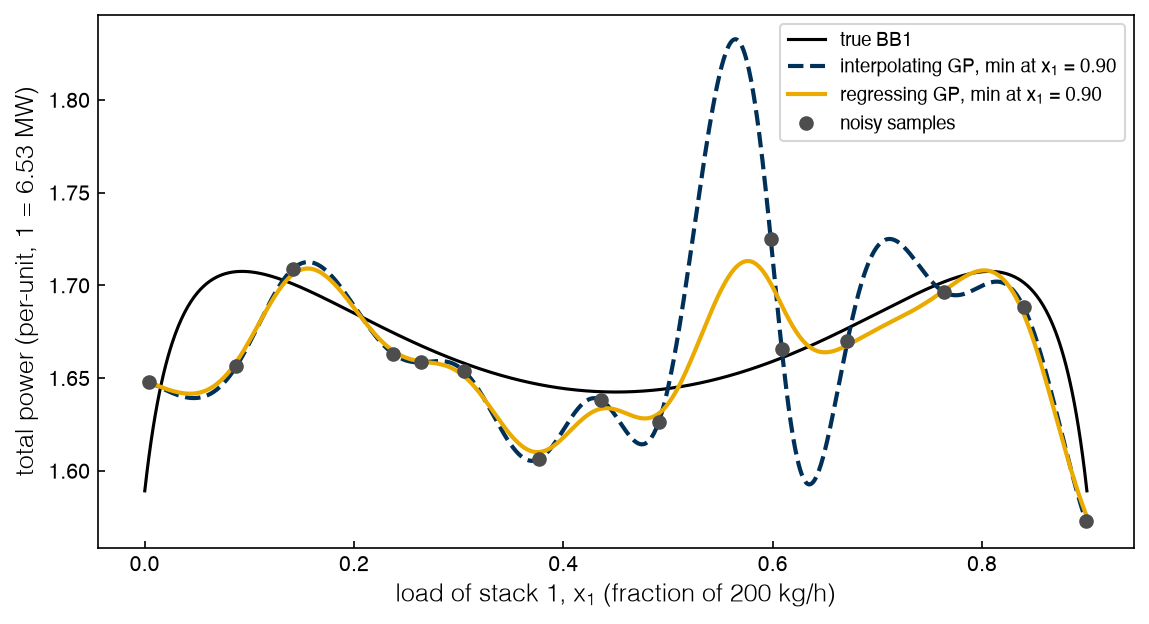

In [1]:
%matplotlib inline
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.stats import qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel
from _lib import electrolyzer as el

F1_STAR = 1.58921                                   # BB1 global optimum (Topic 2.6)
xs = np.linspace(0, 0.9, 901)
f_true = np.array([el.bb1(x) for x in xs])
X1 = np.sort(qmc.LatinHypercube(d=1, seed=0).random(15)[:, 0] * 0.9)[:, None]
y1_clean = np.array([el.bb1(x) for x in X1[:, 0]])

def gp_min(y, alpha):
    """Same fixed kernel every time; alpha = 1e-10 interpolates, alpha = sigma^2 regresses."""
    k = ConstantKernel(0.03, 'fixed') * Matern(0.1, 'fixed', nu=2.5)
    m = GaussianProcessRegressor(k, alpha=alpha).fit(X1, y - y.mean()).predict(xs[:, None]) + y.mean()
    return m, f_true[np.argmin(m)]

for sigma in (0.01, 0.02):
    for name, alpha in (('interpolate', 1e-10), ('regress', sigma**2)):
        c = np.array([gp_min(y1_clean + np.random.default_rng(s).normal(0, sigma, 15), alpha)[1]
                      for s in range(100)])
        print(f"noise {sigma:.2f} ({el.to_mw(sigma)*1e3:3.0f} kW) {name:11s}: mean true cost at minimum "
              f"{c.mean():.4f}, in a global well in {np.mean(c < F1_STAR + 2e-3):.0%} of draws")

y = y1_clean + np.random.default_rng(3).normal(0, 0.02, 15)       # one draw, for the figure
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xs, f_true, 'k', lw=1.5, label='true BB1')
for name, alpha, ls in (('interpolating GP', 1e-10, '--'), ('regressing GP', 0.02**2, '-')):
    m, _ = gp_min(y, alpha)
    ax.plot(xs, m, ls, label=f'{name}, min at $x_1$ = {xs[np.argmin(m)]:.2f}')
ax.plot(X1[:, 0], y, 'o', color='0.3', label='noisy samples')
ax.set_xlabel('load of stack 1, $x_1$ (fraction of 200 kg/h)')
ax.set_ylabel('total power (per-unit, 1 = 6.53 MW)'); ax.legend(fontsize=9);

At 0.01 per-unit noise (65 kW on a 10 MW-class plant) the interpolator already misses the global well in 6% of draws, and at 0.02 (131 kW) it misses in 25% of draws, compared to 3% for the regressor. Since the two models make identical assumptions about shape, the only difference between them is whether they are allowed to miss the data.

More data and more parameters do not by themselves fix a surrogate, and the course notebook shows this with Runge's function $f(x) = 1/(1 + 25x^2)$ on $[-1, 1]$, where we can compare interpolating polynomials through $n$ equally spaced points with least-squares quartics:

:::{admonition} Adapted from the course notebook
:class: note
Adapted from `Optimization with Surrogates (Module 6-7-8).ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT); `np.polyfit` replaces the notebook's Pyomo fits.
:::

In [2]:
runge = lambda x: 1 / (1 + 25 * x**2)
xx = np.linspace(-1, 1, 2001)
for n, deg in ((3, 2), (5, 4), (9, 8), (9, 4), (17, 16), (17, 4)):
    Xr = np.linspace(-1, 1, n)
    err = np.abs(np.polyval(np.polyfit(Xr, runge(Xr), deg), xx) - runge(xx)).max()
    print(f"{n:2d} points, degree {deg:2d} ({'interpolate' if deg == n - 1 else 'regress'}): max error {err:.3f}")

 3 points, degree  2 (interpolate): max error 0.646
 5 points, degree  4 (interpolate): max error 0.438
 9 points, degree  8 (interpolate): max error 1.045
 9 points, degree  4 (regress): max error 0.332
17 points, degree 16 (interpolate): max error 14.394
17 points, degree  4 (regress): max error 0.346


We can see that interpolation gets *worse* as points are added, since the maximum error goes from 0.44 with 5 points to 1.05 with 9 and 14.4 with 17, with the largest errors at the ends of the interval (this is called Runge's phenomenon), while the quartic regression stays near 0.33–0.35. In general the training error falls as parameters are added, but the error on held-out data falls and then rises once the model starts to fit artifacts (overfitting). Regularization, which we discuss below, is the systematic answer to this problem.

:::{exercise}
:label: ex-t35-interp-noise

Repeat with `sigma` = 0.005 and 0.04. Then let the regressing GP estimate the noise itself by adding a `WhiteKernel`; is its estimate close to the true `sigma`?
:::

## Sampling: where to run the stacks

The question of where to sample is the subject of **design of experiments** (DoE). The lectures separate experimental DoE, where physical runs give different results when they are repeated, from computer DoE, where a deterministic simulator can be queried anywhere. A **factorial** design runs every combination of $\ell$ levels per input, which takes $\ell^d$ runs in $d$ dimensions, so it needs only 9 runs for two inputs at three levels but about 9.8 million for ten inputs at five levels. This growth is called the **curse of dimensionality**.

A **Latin hypercube sample** (LHS) of $n$ points avoids this problem by dividing the range of each input into $n$ bins and placing one point in every bin of every input, randomly within that rule. There are variants that maximize the minimum spacing between points ("maximin") or minimize a discrepancy measure, and Sobol sequences are a deterministic alternative, while other space-filling designs include orthogonal-array LHS and sphere packing.

There are three questions that we should answer before choosing any design. The first is *where do the data come from?* Designed data have independent, controllable inputs that are chosen from physics or expert advice, while historical plant data have correlated inputs that nobody controlled and need analysis first (correlations, redundant inputs, transformations, data density), which is the subject of Topics 4.1–4.2. The second is *deterministic or stochastic?* Only a stochastic source needs replicates, and the factorial family (full and fractional factorial, central composite, Box–Behnken, Plackett–Burman) was built for experiments, since it screens effects with few runs, supports statistical tests, and estimates noise from repeated runs. The third is *does the design suit the model?* In the pressure-swing adsorption example from the lectures (two inputs, adsorption and desorption time), a $2^2$ factorial of 4 runs screens the main effects and their interaction but cannot fit a 6-coefficient quadratic, while a $3^2$ design of 9 runs fits it with 3 to spare for validation.

:::{admonition} Adapted from the course notebook
:class: note
The LHS demonstration is adapted from the course notebook `Optimization with Surrogates (Module 6-7-8).ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), modernized from `pyDOE` to `scipy.stats.qmc`.
:::

The inputs of BB2 live in the box $[0, 1]^2$, but stack C must take $x_C = 1.2 - x_A - x_B \in [0, 1]$, and since that material balance is known in advance, any plant runs that violate it are wasted. We can compare three 20-point designs to see how this plays out:

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


random         : min spacing 0.015, discrepancy 0.0238, legal points 9/20
LHS            : min spacing 0.059, discrepancy 0.0031, legal points 11/20
LHS, optimized : min spacing 0.124, discrepancy 0.0013, legal points 13/20


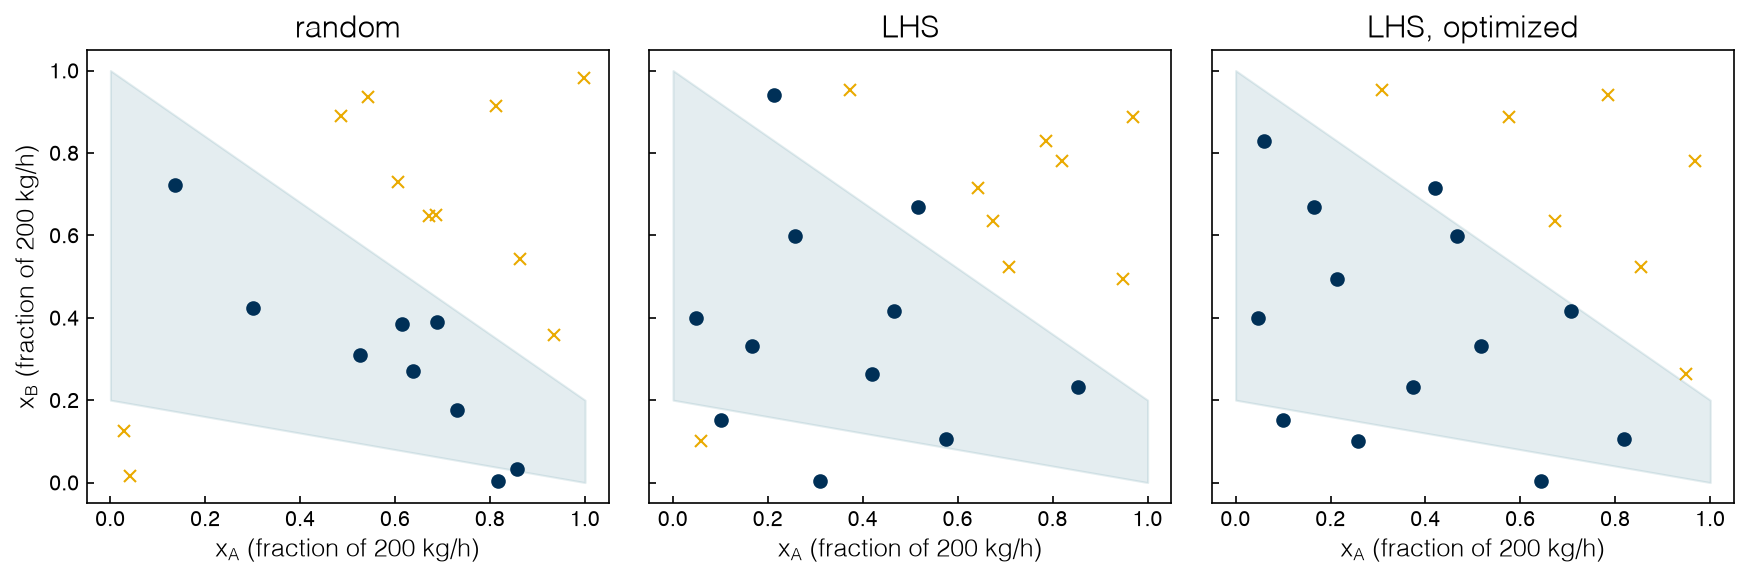

In [3]:
from scipy.spatial.distance import pdist

D = 1.2
def legal(X):
    """Known constraint: stack C's load 1.2 - xA - xB must lie in [0, 1]."""
    xc = D - X[:, 0] - X[:, 1]
    return (xc >= 0) & (xc <= 1)

designs = {'random': np.random.default_rng(0).random((20, 2)),
           'LHS': qmc.LatinHypercube(d=2, seed=0).random(20),
           'LHS, optimized': qmc.LatinHypercube(d=2, seed=0, optimization='random-cd').random(20)}
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
t = np.array([0.0, 1.0])
for ax, (name, Xd) in zip(axs, designs.items()):
    ok = legal(Xd)
    print(f"{name:15s}: min spacing {pdist(Xd).min():.3f}, discrepancy {qmc.discrepancy(Xd):.4f}, "
          f"legal points {ok.sum()}/20")
    ax.fill_between(t, np.clip(0.2 - t, 0, 1), np.clip(1.2 - t, 0, 1), color='C2', alpha=0.15)
    ax.plot(*Xd[ok].T, 'o', color='C0'); ax.plot(*Xd[~ok].T, 'x', color='C1')
    ax.set_title(name); ax.set_xlabel('$x_A$ (fraction of 200 kg/h)')
axs[0].set_ylabel('$x_B$ (fraction of 200 kg/h)');

We can see that the LHS designs are more even than random sampling (they have a larger minimum spacing and a lower discrepancy), but about a third of the box is illegal whatever the design. Here we draw an LHS over the box and discard the illegal points, while in Topic 3.6 we will hand EGO the box with the penalty left in, which is what a black-box method sees when nobody tells it about the constraint.

Space-filling designs ask where we should sample so that a flexible surrogate fits well everywhere, while **model-based DoE** (for example `Pyomo.DoE`) asks which experiments will pin down the unknown parameters of a mechanistic model most precisely. Model-based DoE maximizes a measure of the Fisher information, so its points usually cluster at the edges of the domain rather than filling it. Both are called DoE, and in this course we will only use the space-filling kind.

The next step is validation, which follows DA4CHE Topic 2.2 (*Model Validation*): we fit on a training set, measure the prediction error on a validation set that was left out of the fit, and, if the data allow it, keep a test set that no fitting or tuning decision ever sees. In $k$-fold cross-validation each of $k$ parts of the data is left out once, and similar errors across the folds indicate a model that generalizes.

:::{exercise}
:label: ex-t35-lhs

Record the fraction of legal points for LHS designs of 10, 20, 40 and 80 points. Then draw an LHS over $(x_A, x_C)$ instead: which constraint can it now violate? Is there a pair of coordinates for which an LHS is always legal?
:::

## Linear models, regularization and the LASSO's Lagrangian

*Recap (DA4CHE Topics 1.3 and 2.3).* A **generalized linear model** $\hat y = b_0 + \sum_j b_j X_j(x)$ is linear in its parameters, even though the features $X_j$ can be any functions of $x$. Fitting it by squared error gives a convex QP with a closed form, while fitting it by absolute error gives an LP once the residuals are split into positive and negative parts (Topic 1.4), which is less sensitive to outliers. **Regularization** penalizes the size of the coefficients in order to keep models generalizable, interpretable and easy to optimize. Ridge (L2) regression, $\lambda \lVert b\rVert_2^2$, is convex with a closed form but rarely zeroes coefficients, while the LASSO (L1), $\lambda \lVert b \rVert_1$, does zero them because the L1 ball has corners on the axes where the error contours tend to touch it, so it selects features. The elastic net mixes both. All of these assume that the features are not strongly dependent, and with correlated features the LASSO picks among them almost arbitrarily (Topic 4.2 treats reduced spaces). The example in the lectures starts from 10,000 records of 50 plant sensors and fits a linear (51 terms) or linear-plus-quadratic (101 terms) model with the LASSO in order to find which measurements an operator must watch, and DA4CHE Topic 2.3 (*Complexity Optimization*) has the details.

The lectures also write the LASSO in its original, *constrained* form, a least-squares fit with a budget $t$ on the coefficients:

$$
\min_b \; \frac{1}{2N} \lVert y - Xb \rVert^2 \quad \text{s.t.} \quad \lVert b \rVert_1 \le t, \qquad
\mathcal{L}(b, \mu) = \frac{1}{2N} \lVert y - Xb \rVert^2 + \mu \left( \lVert b \rVert_1 - t \right), \;\; \mu \ge 0.
$$

For a fixed $\mu$, minimizing the Lagrangian over $b$ *is* the penalized LASSO with weight $\mu$, since $-\mu t$ does not depend on $b$. The L1 norm is convex but not differentiable where a coefficient is zero, and that kink is what lets the LASSO set coefficients exactly to zero, but it is also why the LASSO is harder to solve than ridge regression, which has a closed form. Because the problem is convex, strong duality holds ({doc}`../2-nonlinear_mixed_integer/Topic2.3-Duality`), and the multiplier keeps its meaning from {doc}`../2-nonlinear_mixed_integer/Topic2.2-Lagrange_Multipliers_and_KKT_Conditions`, which is the rate at which the best achievable fitting error falls as the budget $t$ is relaxed. We can check this on a degree-8 polynomial that is fitted to noisy BB1 data, using the penalized LASSO for three values of $\alpha$ and then the constrained form with $t = \lVert b \rVert_1$:

In [4]:
from scipy.optimize import minimize
from sklearn.linear_model import Lasso

y = y1_clean + np.random.default_rng(0).normal(0, 0.02, 15)
F = np.vander(2 * X1[:, 0] / 0.9 - 1, 9, increasing=True)[:, 1:]    # features z, ..., z^8, z in [-1, 1]
F = (F - F.mean(0)) / F.std(0); yc = y - y.mean(); N, M = F.shape

for alpha in (1e-4, 1e-3, 1e-2):
    b = Lasso(alpha=alpha, fit_intercept=False, max_iter=200000, tol=1e-12).fit(F, yc).coef_
    t = np.abs(b).sum()
    loss = lambda v: ((yc - F @ (v[:M] - v[M:]))**2).sum() / (2 * N)     # b = p - q, p, q >= 0
    res = minimize(loss, np.full(2 * M, 1e-3), method='SLSQP', bounds=[(0, None)] * (2 * M),
                   constraints=[{'type': 'ineq', 'fun': lambda v: t - v.sum()}],
                   options={'ftol': 1e-14, 'maxiter': 2000})
    print(f"alpha = {alpha:.0e}: {np.sum(np.abs(b) > 1e-8)} of {M} features kept, t = {t:.4f}, "
          f"max |b_pen - b_con| = {np.abs(b - (res.x[:M] - res.x[M:])).max():.1e}, "
          f"budget multiplier = {res.multipliers[0]:.2e}")

alpha = 1e-04: 6 of 8 features kept, t = 0.2119, max |b_pen - b_con| = 8.8e-07, budget multiplier = 1.00e-04
alpha = 1e-03: 3 of 8 features kept, t = 0.0963, max |b_pen - b_con| = 5.0e-08, budget multiplier = 1.00e-03
alpha = 1e-02: 2 of 8 features kept, t = 0.0131, max |b_pen - b_con| = 1.9e-12, budget multiplier = 1.00e-02


We can see that the two forms agree to solver precision and that the multiplier on the budget equals $\alpha$ each time, and that a tighter budget keeps fewer features.

:::{exercise}
:label: ex-t35-lasso-sensitivity

For $\alpha = 10^{-3}$, raise $t$ by 1%, re-solve the constrained problem, and compare the change in fitting error with the prediction $-\mu\,\Delta t$. Repeat for ridge regression written as a budget on $\sum b_j^2$.
:::

## Training is an optimization problem

The lectures place surrogates inside **machine learning**, where supervised learning fits inputs to known outputs and unsupervised learning finds structure in the inputs alone. Supervised problems are either regression, where the output is continuous (as in our surrogates), or classification, where the output is whether a point belongs to a class (as in the feasibility classifier of Topic 3.6). Unsupervised problems include dimensionality reduction (Topic 4.2) and clustering, and the two kinds are often combined, while reinforcement learning, in which a model keeps learning as it acts, is outside this course. Every such model, including linear regression, needs data, can represent only the shapes that its assumptions allow, is trustworthy only where the data are, and is fitted by solving

$$
\min_{\theta} \; \sum_{k=1}^{N} \ell\big(y_k, \hat f(x_k; \theta)\big) + \lambda\, R(\theta),
$$

where $\ell$ is an error measure (squared, absolute, or the $\varepsilon$-insensitive loss of SVR below) and $R$ is an optional regularizer. This is **optimization for training**, where the parameters $\theta$ are the variables and the data are fixed, so a linear model with squared error gives a convex QP while a neural network gives a non-convex NLP. In **optimization with an embedded trained model** the roles swap, since $\theta$ is fixed and the process inputs $x$ are the variables, and we solve $\min_x \hat f(x;\theta)$ subject to the constraints of the plant. The class of this problem (LP to MINLP) depends only on the equations of the model, which means that Topics 1.1–2.6 apply unchanged. Topic 3.6 does this with a GP, and {doc}`../4-data_driven_modeling/Topic4.3-Hybrid_Modeling` embeds a neural network in Pyomo.

**Hyperparameters** (the weight $\lambda$, the length scale of a kernel, the layers of a network) sit outside the inner problem, and since many of them are discrete, training them jointly would give an MINLP. Instead, an outer search wraps the inner problem, which can be an exhaustive grid (`GridSearchCV`), random draws (`RandomizedSearchCV`), or a genetic algorithm (Topic 3.3; e.g. `sklearn-genetic-opt`), since sample-based methods suit a map with no closed form. The inner problem is solved locally by **gradient descent** (Cauchy, 1847), where the fixed step acts like a fixed trust-region radius (Topic 3.2), or by **stochastic gradient descent** (SGD, from 1950s stochastic approximation), which uses the gradient on a random mini-batch at each step and makes very large models trainable. Below we fit a six-coefficient quadratic of BB2 three ways, using the legal points of a 40-point LHS:

26 legal training points; least-squares MSE 9.97e-04; condition number of Phi^T Phi 3153
after 3000 epochs, excess MSE: gradient descent 7.4e-04, SGD 4.5e-05


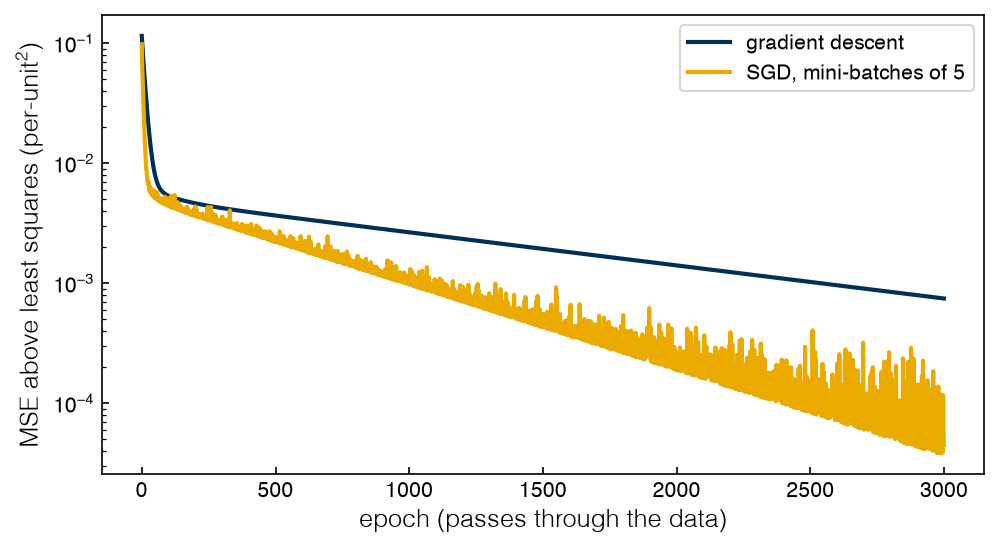

In [5]:
from sklearn.preprocessing import PolynomialFeatures

Xall = qmc.LatinHypercube(d=2, seed=1).random(40)
Xtr = Xall[legal(Xall)]; ytr = np.array([el.bb2(x) for x in Xtr])
Phi = PolynomialFeatures(2).fit_transform(Xtr)                    # 1, xA, xB, xA^2, xA xB, xB^2
mse = lambda th, A=Phi, b=ytr: np.mean((A @ th - b)**2)
th_ls = np.linalg.lstsq(Phi, ytr, rcond=None)[0]
step = 1 / np.linalg.eigvalsh(2 * Phi.T @ Phi / len(ytr)).max()   # 1 / Lipschitz constant of the gradient
print(f"{len(Xtr)} legal training points; least-squares MSE {mse(th_ls):.2e}; "
      f"condition number of Phi^T Phi {np.linalg.cond(Phi.T @ Phi):.0f}")

th_gd, th_sgd, rng, hist = np.zeros(6), np.zeros(6), np.random.default_rng(0), []
for epoch in range(3000):
    th_gd -= step * 2 * Phi.T @ (Phi @ th_gd - ytr) / len(ytr)
    for idx in np.array_split(rng.permutation(len(ytr)), len(ytr) // 5):    # mini-batches of ~5
        th_sgd -= 0.5 * step * 2 * Phi[idx].T @ (Phi[idx] @ th_sgd - ytr[idx]) / len(idx)
    hist.append((mse(th_gd) - mse(th_ls), mse(th_sgd) - mse(th_ls)))
hist = np.array(hist)
print(f"after 3000 epochs, excess MSE: gradient descent {hist[-1, 0]:.1e}, SGD {hist[-1, 1]:.1e}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(hist[:, 0], label='gradient descent'); ax.semilogy(hist[:, 1], label='SGD, mini-batches of 5')
ax.set_xlabel('epoch (passes through the data)'); ax.set_ylabel('MSE above least squares (per-unit$^2$)')
ax.legend();

After 3,000 passes gradient descent is still 7.4e-4 above the optimum, which is comparable to the MSE of the optimum itself (1.0e-3). The cause is conditioning (Topic 2.1), since with a condition number near 3,200 a step that is safe along the steepest direction is tiny along the flattest one. SGD takes five steps per pass and gets further along (4.5e-5), but its steps are noisy, and with a constant step size it would eventually stall at a noise floor. For six parameters the closed form is the right tool, but for a network with a million parameters there is no closed form, and SGD is the right tool.

:::{exercise}
:label: ex-t35-sgd

Give SGD a decaying step $\eta_k = \eta_0/(1 + k/100)$. Then standardize the five non-constant columns of `Phi`, and report the new condition number and the number of gradient-descent steps needed to reach an excess MSE of $10^{-8}$.
:::

## Gaussian processes and neural networks

*Recap (DA4CHE Topics 2.1, 6.3 and 6.4).* A **Gaussian process** (GP), also called **kriging** after the mining engineer Danie Krige (formalized by Georges Matheron around 1960 to locate mineral deposits), is by default an interpolator. In the form used in the lectures (Jones et al., 1998), a constant mean $\mu$ is enough because the error is modeled instead of being assumed random, so that the errors at two points are correlated through $\exp\big(-\sum_j \theta_j |x_j - x'_j|^{p_j}\big)$, which tends to 1 as the points approach and to 0 as they separate. The predictor is $\hat y(x) = \mu + \sum_i w_i \exp\big(-\sum_j \theta_j |x_j^{(i)} - x_j|^{p_j}\big)$, where the parameters are $\mu$, $w_i$ and $\theta_j$, and a large $\theta_j$ means that the output is sensitive to $x_j$. The exponent $p_j$, which is usually 2, is a hyperparameter, and with $p_j = 2$ this is the RBF kernel with **length scale** $\ell_j = 1/\sqrt{2\theta_j}$. The GP also returns a standard deviation $\hat\sigma(x)$ that is zero at the samples and grows between them. scikit-learn fits the amplitude and length scales of the kernel by maximizing the marginal likelihood, which is a non-convex problem whose cost grows with the cube of the number of samples, and fitting gets harder with more dimensions.

A **neural network** is built from **perceptrons**, where each one computes $\sigma(b + \sum_i w_i x_i)$ with an activation function $\sigma$ such as tanh, the sigmoid, ELU, or the identity at the output, and nesting them gives $\hat f(x) = W_L\,\sigma(\cdots \sigma(W_1 x + b_1) \cdots) + b_L$. Feedforward networks are universal approximators (Hornik, Stinchcombe and White, 1989), they approximate typical unit operations well (Henao and Maravelias, 2011), and one network can have several outputs.

The weights and biases are the parameters, while the number of layers, the nodes per layer and the activation are hyperparameters. There are more decisions that precede training, including the initialization, the training algorithm (gradient descent, Newton's method, Levenberg–Marquardt, or SGD variants such as Adam and Nadam) and its learning rate, regularization such as early stopping, and the size, sampling, scaling and choice of inputs of the data. Hyperparameters are chosen by grid search or a genetic algorithm. When a network disappoints in practice, the cause is usually its training rather than what it can represent.

There are two points that matter for optimization. The first is that we should **scale** inputs and outputs to the same order before fitting, where min-max scaling $x' = (x - x_{\min})/(x_{\max} - x_{\min})$ maps to $[0, 1]$, standardization $x' = (x - \bar x)/s_x$ gives zero mean and unit variance, and both are inverted after prediction. If the data are not scaled, the distances in a GP are dominated by the largest-valued input and the coefficients mislead, so that in the adsorption fit of the course notebook in seconds (25–250 s), a quadratic coefficient near $-4.8 \times 10^{-5}$ contributes about 3 purity points at 250 s. Our per-unit inputs are already scaled, and `normalize_y` standardizes the output of the GP. The second point is that $\hat\sigma(x)$ tells an optimizer where the surrogate does not yet know, which is why Topic 3.6 uses GPs for adaptive sampling, and the length scale controls $\hat\sigma$.

:::{exercise}
:label: ex-t35-lengthscale

Fit GPs to the noise-free BB1 samples `X1, y1_clean` with the Matérn 5/2 length scale fixed at 0.03, 0.1 and 1.0, and plot each mean with a $\pm 2\hat\sigma$ band. Which is overconfident between samples, and which is nearly useless?
:::

## Support vector regression and its dual

DA4CHE does not cover **support vector regression** (SVR), which grew from Vapnik's statistical learning theory (the 1960s to 1990s) and from support vector machines for classification, and which often generalizes as well as or better than competing methods. Its training problem is also the cleanest use of Topic 2.3 in the course, so we will work through it in full in the order of the lectures.

**Primal.** For a linear model $\hat f(x) = w^\top x + b$ and samples $(x_i, y_i)$, SVR wants every prediction to be within $\varepsilon$ of its sample and the function to be as flat as possible, as measured by $\tfrac12\lVert w\rVert^2$. That hard tube can be infeasible, so the **soft margin** adds slacks $\xi_i, \xi_i^*$ that let points sit above or below the tube, and since merely bounding the slacks would be no better than choosing a larger $\varepsilon$, they are instead penalized in the objective at a price $C$:

$$
\min_{w, b, \xi, \xi^*} \; \tfrac12 \lVert w \rVert^2 + C \sum_i (\xi_i + \xi_i^*) \quad \text{s.t.} \quad
y_i - w^\top x_i - b \le \varepsilon + \xi_i, \;\; w^\top x_i + b - y_i \le \varepsilon + \xi_i^*, \;\; \xi_i, \xi_i^* \ge 0.
$$

The two objective terms have different scales, which is why $C$ is a hyperparameter. At the optimum each slack equals the **$\varepsilon$-insensitive loss** of its sample, $|r|_\varepsilon = \max(0, |r| - \varepsilon)$ for the residual $r = y_i - \hat f(x_i)$, so errors inside the tube cost nothing while errors beyond it cost linearly. The variables are $w$, $b$, $\xi$ and $\xi^*$, while $C$ and $\varepsilon$ are parameters, and since the problem is a convex QP, strong duality holds.

**Lagrangian.** With multipliers $\alpha_i, \alpha_i^* \ge 0$ on the tube constraints and $\eta_i, \eta_i^* \ge 0$ on the slack signs ($4N$ in all),

$$
\mathcal{L} = \tfrac12 \lVert w \rVert^2 + C \sum_i (\xi_i + \xi_i^*) - \sum_i (\eta_i \xi_i + \eta_i^* \xi_i^*)
- \sum_i \alpha_i (\varepsilon + \xi_i - y_i + w^\top x_i + b) - \sum_i \alpha_i^* (\varepsilon + \xi_i^* + y_i - w^\top x_i - b).
$$

**Stationarity.** Minimizing over the primal variables gives

$$
w = \sum_i (\alpha_i - \alpha_i^*)\, x_i, \qquad \sum_i (\alpha_i - \alpha_i^*) = 0, \qquad \eta_i = C - \alpha_i, \qquad \eta_i^* = C - \alpha_i^*.
$$

Since $\eta \ge 0$, the last two become $0 \le \alpha_i, \alpha_i^* \le C$, and the $\eta$'s disappear.

**Dual.** When we substitute these back, the $\xi$ and $b$ terms cancel, which leaves a concave QP in $2N$ multipliers:

$$
\max_{\alpha, \alpha^*} \; -\tfrac12 \sum_{i,j} (\alpha_i - \alpha_i^*)(\alpha_j - \alpha_j^*)\, x_i^\top x_j - \varepsilon \sum_i (\alpha_i + \alpha_i^*) + \sum_i y_i (\alpha_i - \alpha_i^*)
\quad \text{s.t.} \quad \sum_i (\alpha_i - \alpha_i^*) = 0, \;\; 0 \le \alpha_i, \alpha_i^* \le C.
$$

The size of the dual depends on the number of samples and not on the dimension of $x$, which is why SVR suits problems with many inputs and few points, and although the dual grows when there are many points, only the support vectors appear in the final model. The prediction is $\hat f(x) = \sum_i (\alpha_i - \alpha_i^*)\, x_i^\top x + b$.

**Complementary slackness.** A sample that is strictly inside the tube has $\alpha_i = \alpha_i^* = 0$ and drops out, so only the samples on or outside the tube, which are called the **support vectors**, carry weight. A sample with $0 < \alpha_i < C$ has $\eta_i > 0$, and hence $\xi_i = 0$, so it sits exactly on the edge of the tube, $y_i - \hat f(x_i) = \varepsilon$, and this gives us $b$. Finally, $\alpha_i \alpha_i^* = 0$, since no point can be both above and below the tube.

**Kernel trick.** The data enter the dual only through the inner products $x_i^\top x_j$, so mapping $x$ to polynomial features, which would make the primal strongly nonlinear, only changes these inner products in the dual. If we replace them by a kernel, either a polynomial kernel or the Gaussian kernel $k(x_i, x_j) = \exp(-\gamma \lVert x_i - x_j \rVert^2)$, we get a nonlinear SVR, $\hat f(x) = \sum_i (\alpha_i - \alpha_i^*)\, k(x_i, x) + b$, with a dual of the same size, even though the equivalent primal feature space of the Gaussian kernel is infinite-dimensional. With this kernel the SVR has the same form as a GP mean, and the only difference is the way that the weights are chosen. We can solve the kernel dual for the 15 noisy BB1 samples and compare with scikit-learn:

In [6]:
from sklearn.svm import SVR

zs = (X1[:, 0] / 0.9)[:, None]; ys = (y - y.mean()) / y.std()      # scaled input, standardized output
N = len(ys); C, eps, gamma = 10.0, 0.1, 20.0
K = np.exp(-gamma * (zs - zs.T)**2)
neg_dual = lambda v: 0.5 * (v[:N] - v[N:]) @ K @ (v[:N] - v[N:]) + eps * v.sum() - ys @ (v[:N] - v[N:])
grad = lambda v: np.concatenate([K @ (v[:N] - v[N:]) - ys + eps, -(K @ (v[:N] - v[N:]) - ys) + eps])
res = minimize(neg_dual, np.zeros(2 * N), jac=grad, method='SLSQP', bounds=[(0, C)] * (2 * N),
               constraints=[{'type': 'eq', 'fun': lambda v: (v[:N] - v[N:]).sum()}],
               options={'ftol': 1e-14, 'maxiter': 1000})
a, a_star = res.x[:N], res.x[N:]; beta = a - a_star
edge = (a > 1e-6) & (a < C - 1e-6)                                  # 0 < alpha_i < C: on the tube edge
b = np.mean(ys[edge] - eps - K[edge] @ beta)
print(f"support vectors {np.sum(np.abs(beta) > 1e-6)} of {N}; max alpha*alpha_star {(a * a_star).max():.1e}")
print(f"b from the tube edge {b:.5f}; solver multiplier of sum(alpha - alpha*) = 0: {res.multipliers[0]:.5f}")
sk = SVR(kernel='rbf', gamma=gamma, C=C, epsilon=eps, tol=1e-10).fit(zs, ys)
zz = np.linspace(0, 1, 201)[:, None]
print(f"scikit-learn: {len(sk.support_)} support vectors, b = {sk.intercept_[0]:.5f}, max prediction "
      f"difference {np.abs(np.exp(-gamma * (zz - zs.T)**2) @ beta + b - sk.predict(zz)).max():.1e}")

support vectors 13 of 15; max alpha*alpha_star 1.0e-14
b from the tube edge -1.10409; solver multiplier of sum(alpha - alpha*) = 0: 1.10409


scikit-learn: 13 support vectors, b = -1.10409, max prediction difference 6.2e-07


Our dual reproduces the scikit-learn model to solver precision, with $\alpha_i\alpha_i^* = 0$ as complementary slackness requires. The equality multiplier of the dual is $-b$ (in the sign convention of scipy), because the stationarity condition for $b$ produced that constraint and the dual hands $b$ back as its multiplier, which is the symmetry of Topic 2.3. With $\varepsilon = 0.1$, 13 of 15 samples are support vectors, and a wider tube is sparser.

:::{exercise}
:label: ex-t35-svr-dual

Re-solve with $\varepsilon$ = 0.3, 0.5 and 1.0 and report the number of support vectors and the error against the true BB1. Then use the linear kernel, recover $w$ from the first stationarity condition, and check it against `SVR(kernel='linear')`.
:::

## Four surrogates on one black box

We now fit the four families once each to the BB2 training set from above and score them on 500 legal test points. The four are the quadratic; a GP with a Matérn 5/2 kernel and one length scale per input; a neural network with two hidden layers of 16 tanh units, trained by L-BFGS; and an SVR whose $C$ and $\gamma$ come from a 5-fold cross-validated grid search, which is an outer hyperparameter search around the inner dual QP.

:::{admonition} Adapted from the course notebook
:class: note
The scikit-learn GP, MLP and SVR fits are adapted from the course notebook `Optimization with Surrogates (Module 6-7-8).ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), with current scikit-learn calls and BB2 in place of the notebook's test function.
:::

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


quadratic       : RMSE  314 kW, worst 1.34 MW, 10 worst points a median 0.004 from an edge
GP (Matérn 5/2) : RMSE  179 kW, worst 0.86 MW, 10 worst points a median 0.004 from an edge
neural network  : RMSE  119 kW, worst 0.65 MW, 10 worst points a median 0.004 from an edge
SVR (CV grid)   : RMSE  224 kW, worst 1.09 MW, 10 worst points a median 0.004 from an edge
typical test point: 0.100 from an edge; SVR chose {'C': 100, 'gamma': 1}


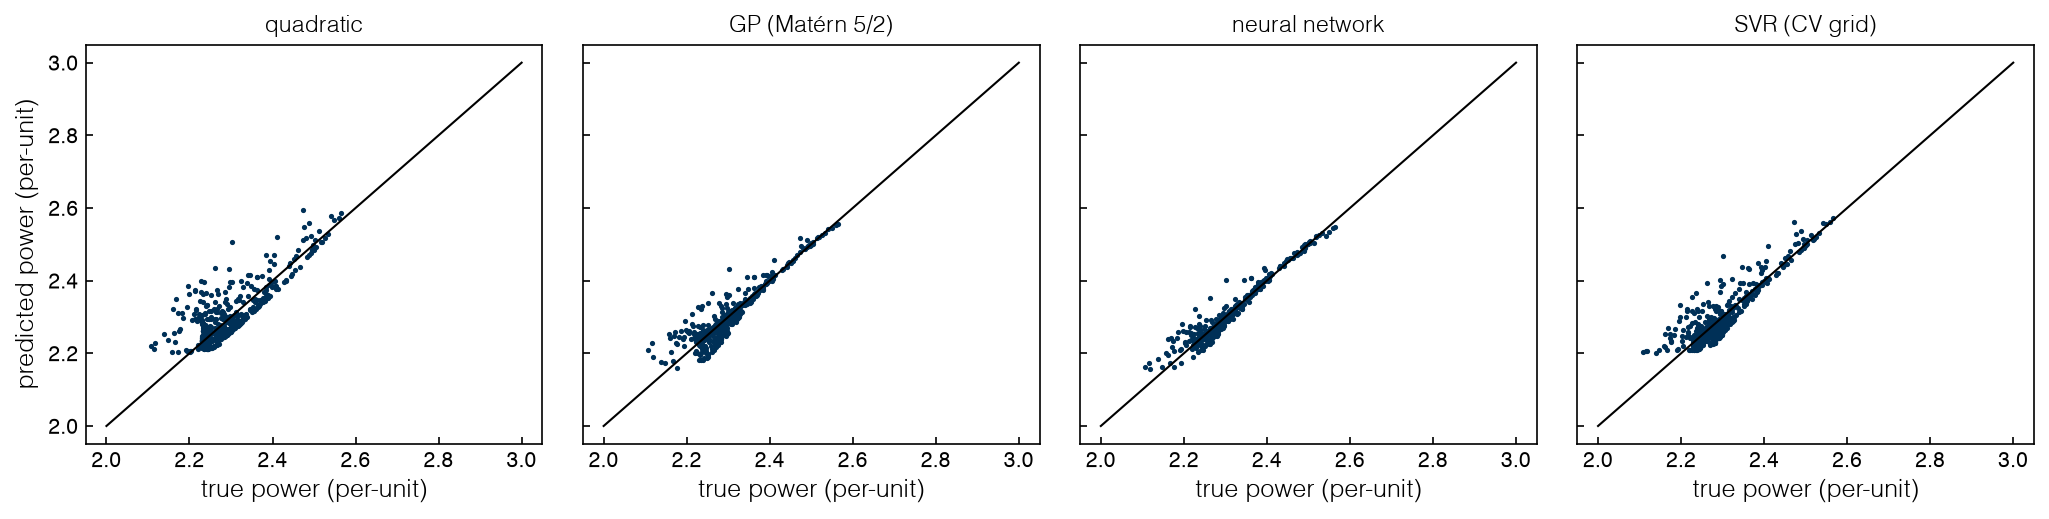

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

Xte = np.random.default_rng(7).random((2000, 2)); Xte = Xte[legal(Xte)][:500]
yte = np.array([el.bb2(x) for x in Xte])
def edge_distance(X):                                   # distance to the nearest edge of the legal region
    xc = D - X[:, 0] - X[:, 1]
    return np.min([X[:, 0], 1 - X[:, 0], X[:, 1], 1 - X[:, 1], xc / np.sqrt(2), (1 - xc) / np.sqrt(2)], axis=0)

std_y = lambda model: TransformedTargetRegressor(model, transformer=StandardScaler())
models = {'quadratic': make_pipeline(PolynomialFeatures(2), LinearRegression()),
          'GP (Matérn 5/2)': GaussianProcessRegressor(ConstantKernel() * Matern([0.3, 0.3], nu=2.5),
                                     normalize_y=True, n_restarts_optimizer=3, random_state=0),
          'neural network': std_y(MLPRegressor(hidden_layer_sizes=(16, 16), activation='tanh',
                                     solver='lbfgs', max_iter=5000, random_state=0)),
          'SVR (CV grid)': std_y(GridSearchCV(SVR(kernel='rbf', epsilon=0.01),
                                     {'C': [1, 10, 100, 1000], 'gamma': [0.3, 1, 3, 10]}, cv=5))}
fig, axs = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, (name, mdl) in zip(axs, models.items()):
    err = mdl.fit(Xtr, ytr).predict(Xte) - yte
    rmse, worst10 = np.sqrt(np.mean(err**2)), np.argsort(np.abs(err))[-10:]
    print(f"{name:16s}: RMSE {el.to_mw(rmse)*1e3:4.0f} kW, worst {el.to_mw(np.abs(err).max()):.2f} MW, "
          f"10 worst points a median {np.median(edge_distance(Xte[worst10])):.3f} from an edge")
    ax.plot(yte, yte + err, '.', ms=3); ax.plot([2, 3], [2, 3], 'k', lw=1)
    ax.set_title(name, fontsize=11); ax.set_xlabel('true power (per-unit)')
axs[0].set_ylabel('predicted power (per-unit)')
print(f"typical test point: {np.median(edge_distance(Xte)):.3f} from an edge; "
      f"SVR chose {models['SVR (CV grid)'].regressor_.best_params_}")

Here the network has the lowest held-out RMSE (119 kW), followed by the GP (179 kW), the SVR (224 kW) and the quadratic (314 kW), although another sample set could reorder them. All four fail in the same place, since their ten worst test points lie a median 0.004 per-unit from an edge of the legal region, compared to 0.10 for a typical test point. The cheapest split for BB2, about $(x_A, x_B) = (0.70, 0)$ at a cost of 2.0818, is on the edge $x_B = 0$ where stack B is off, and a space-filling design puts few points near any edge. A surrogate that is accurate on average but wrong at the optimum is a poor surrogate for optimization, which is why Topic 3.6 samples adaptively and returns to the edges.

:::{exercise}
:label: ex-t35-compare

Add the corners of the legal region and four points on its edges to the training set, refit all four models, and report the change in RMSE and worst error.
:::

## Summary

- A surrogate is a cheap, equation-based model of an expensive black box, built so that the optimizers of Topics 1.1–2.6 apply again.
- Interpolate noise-free simulations and regress noisy measurements. Adding interpolation points can make a polynomial surrogate worse.
- Latin hypercubes spread a fixed budget of samples evenly and avoid the curse of dimensionality of factorial designs, and known constraints should shape the design. Model-based DoE answers a different question: which experiments best identify a model's parameters.
- Optimization *for* training varies the parameters, and optimization *with* a trained model varies the inputs. Hyperparameters sit in an outer search around the training problem.
- The penalized LASSO is the Lagrangian of the constrained LASSO, with the penalty weight as the budget's multiplier. SVR is trained through its dual, whose size depends only on the number of samples.
- All four surrogates of BB2 are least accurate at the edges of the legal region, which is where the optimum is.

## Additional Reading

- A. I. J. Forrester, A. Sóbester and A. J. Keane, *Engineering Design via Surrogate Modelling: A Practical Guide*, Wiley (2008). Sampling plans, kriging and SVR.
- A. J. Smola and B. Schölkopf, "A tutorial on support vector regression," *Statistics and Computing* 14, 199–222 (2004).
- R. Tibshirani, "Regression shrinkage and selection via the lasso," *Journal of the Royal Statistical Society, Series B* 58, 267–288 (1996).
- M. D. McKay, R. J. Beckman and W. J. Conover, "A comparison of three methods for selecting values of input variables in the analysis of output from a computer code," *Technometrics* 21, 239–245 (1979).
- C. E. Rasmussen and C. K. I. Williams, *Gaussian Processes for Machine Learning*, MIT Press (2006).